In [1]:
import pandas as pd
import numpy as np
from vis.utils_motifs import motif_to_fwords, get_node_importance
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

In [2]:
OUT_DIR = Path("results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")

In [3]:
file_name = OUT_DIR / "expl_attributes_none_node_comp_top0p050nd.csv"
df = pd.read_csv(file_name)
df

,node,word,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,0,a,180,1,0.005556,178,14,0.078652,0.073096
1,1,about,180,0,0.000000,178,51,0.286517,0.286517
2,2,above,180,9,0.050000,178,5,0.028090,-0.021910
3,4,after,180,5,0.027778,178,45,0.252809,0.225031
4,5,afterwards,180,38,0.211111,178,3,0.016854,-0.194257
...,...,...,...,...,...,...,...,...,...
85,109,indeed,180,17,0.094444,178,39,0.219101,0.124657
86,111,instead,180,25,0.138889,178,4,0.022472,-0.116417
87,112,into,180,8,0.044444,178,0,0.000000,-0.044444
88,113,is,180,12,0.066667,178,0,0.000000,-0.066667


In [4]:
def plot_node_differences(node_df, top_n=15):

    plot_df = (
        node_df
        .dropna(subset=["difference"])
        .assign(abs_diff=lambda x: x["difference"].abs())
        .nlargest(top_n, "abs_diff")
        .sort_values("difference")
    )

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=plot_df,
        x="difference",
        y="word",
        hue="word",
        palette="vlag",
        legend=False,
    )

    plt.axvline(0, color="black", linestyle="--")

    plt.xlabel("Selection rate difference (Machine - Human)")
    plt.ylabel("Function word")
    plt.title("Function Words with Largest Importance Differences")

    plt.tight_layout()
    plt.show()

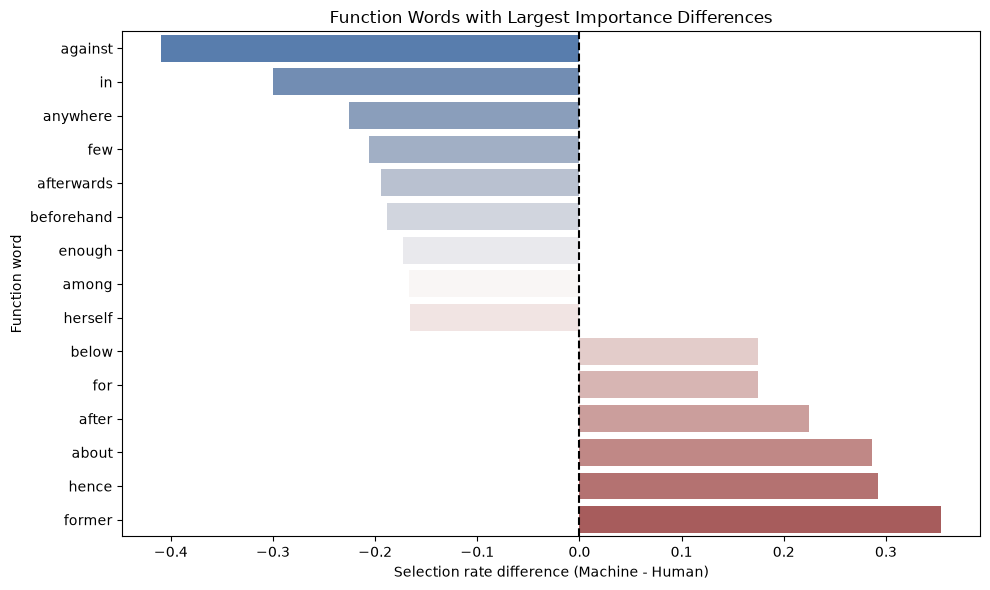

In [5]:
plot_node_differences(df)

In [6]:
results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_attributes_none.pth",
    map_location="cpu",
    weights_only=False
)

In [7]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float))

    n = len(values)

    if n == 0:
        return np.nan

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def analyze_node_uniformity(results):

    rows = []

    for result in results:

        node_mask = result["node_mask"]

        if node_mask is None:
            continue

        importance = get_node_importance(node_mask)

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",
            "mean": np.mean(importance),
            "std": np.std(importance),
            "gini": gini_coefficient(importance),
            "p90_p10": (
                np.percentile(importance, 90)
                - np.percentile(importance, 10)
            ),
        })

    df = pd.DataFrame(rows)

    print("\nSummary across graphs:")
    print(
        df[["mean", "std", "gini", "p90_p10"]]
        .describe()
        .round(3)
    )

    return df

In [11]:
df_uniform = analyze_node_uniformity(results)


Summary across graphs:
          mean      std     gini  p90_p10
count  360.000  360.000  360.000  360.000
mean     0.230    0.019    0.039    0.049
std      0.114    0.018    0.033    0.048
min      0.142    0.002    0.009    0.005
25%      0.145    0.004    0.015    0.009
50%      0.145    0.005    0.017    0.011
75%      0.343    0.037    0.060    0.095
max      0.455    0.055    0.117    0.144


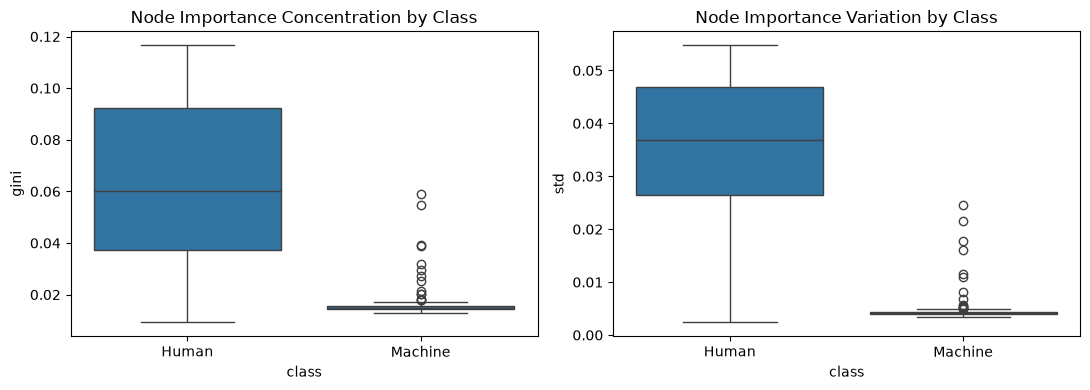

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=df_uniform,
    x="class",
    y="gini",
    ax=axes[0]
)

axes[0].set_title("Node Importance Concentration by Class")

sns.boxplot(
    data=df_uniform,
    x="class",
    y="std",
    ax=axes[1]
)

axes[1].set_title("Node Importance Variation by Class")

plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import pandas as pd
import torch


def aggregate_feature_importance(results, correct_only=True):
    """
    Aggregate GNNExplainer node feature masks into
    count, frequency, and embedding importance.

    Assumes:
        Feature 0 = count
        Feature 1 = frequency
        Features 2: = embeddings
    """

    rows = []

    if isinstance(results, pd.DataFrame):
        records = results.to_dict("records")
    else:
        records = results

    for result in records:

        if correct_only and result["label"] != result["pred"]:
            continue

        node_mask = result["node_mask"]

        if node_mask is None:
            continue

        mask = torch.as_tensor(node_mask).detach().cpu().numpy()

        if mask.ndim != 2 or mask.shape[1] < 3:
            raise ValueError(
                f"Unexpected node mask shape: {mask.shape}"
            )

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",

            "count": mask[:, 0].mean(),
            "frequency": mask[:, 1].mean(),
            "embedding": mask[:, 2:].mean(),

            # Variation within each feature group
            "count_std": mask[:, 0].std(),
            "frequency_std": mask[:, 1].std(),
            "embedding_std": mask[:, 2:].std(),
        })

    return pd.DataFrame(rows)

In [14]:
df_features = aggregate_feature_importance(results, correct_only=True)

In [15]:
df_features

,row,class,count,frequency,embedding,count_std,frequency_std,embedding_std
0,13,Human,0.188659,0.191573,0.441469,0.252461,0.256507,0.092058
1,17,Human,0.282034,0.281353,0.434439,0.257557,0.257969,0.095484
2,20,Human,0.187717,0.184462,0.344425,0.248614,0.244642,0.120929
3,22,Human,0.236627,0.236027,0.410394,0.260517,0.259822,0.105831
4,28,Human,0.232119,0.213047,0.240144,0.249840,0.233346,0.101825
...,...,...,...,...,...,...,...,...
353,2372,Machine,0.036623,0.032628,0.146956,0.069613,0.061431,0.031615
354,2379,Machine,0.057616,0.051800,0.147177,0.079144,0.071037,0.030178
355,2381,Machine,0.068123,0.062447,0.146586,0.075460,0.068928,0.031478
356,2383,Machine,0.050132,0.045098,0.146537,0.071579,0.063927,0.030342


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_feature_importance(df_features):

    plot_df = df_features.melt(
        id_vars=["row", "class"],
        value_vars=["count", "frequency", "embedding"],
        var_name="Feature group",
        value_name="Importance",
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Overall importance
    sns.boxplot(
        data=plot_df,
        x="Feature group",
        y="Importance",
        ax=axes[0],
    )

    axes[0].set_title("Feature Importance Across Graphs")
    axes[0].set_ylabel("Mean GNNExplainer mask value")

    # Comparison between classes
    sns.boxplot(
        data=plot_df,
        x="Feature group",
        y="Importance",
        hue="class",
        ax=axes[1],
    )

    axes[1].set_title("Feature Importance by Class")
    axes[1].set_ylabel("Mean GNNExplainer mask value")

    plt.tight_layout()
    plt.show()

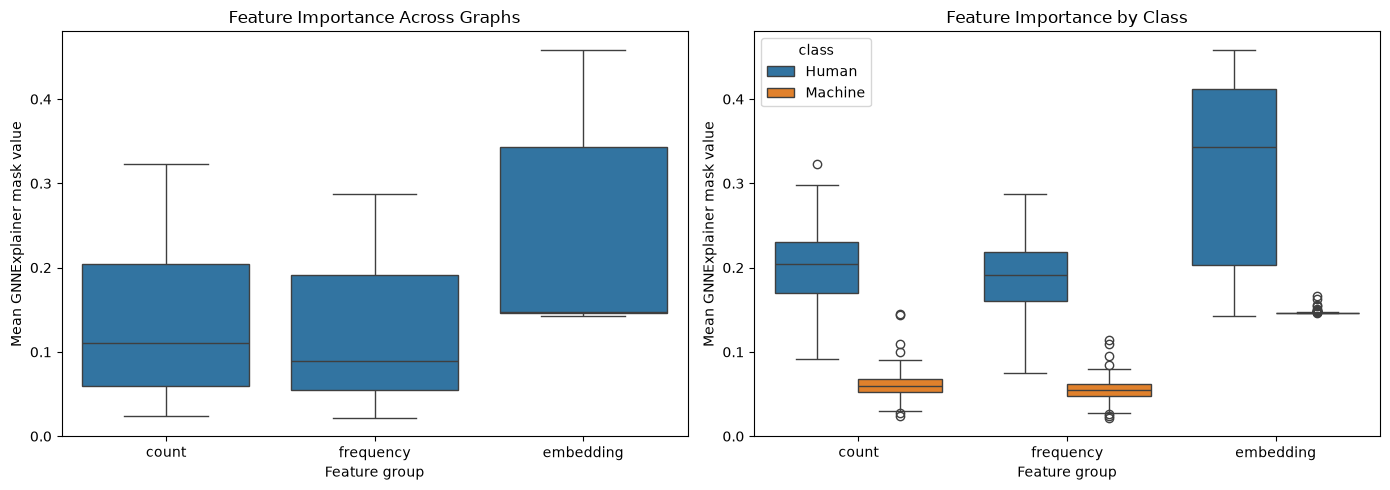

In [17]:
plot_feature_importance(df_features)

In [18]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float).flatten())

    n = len(values)

    if n == 0 or not np.all(np.isfinite(values)):
        return np.nan

    if np.any(values < 0):
        raise ValueError("Gini requires nonnegative values.")

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def analyze_feature_uniformity(results, correct_only=True):

    rows = []

    for result in results:

        if correct_only and result["label"] != result["pred"]:
            continue

        mask = torch.as_tensor(
            result["node_mask"]
        ).detach().cpu().numpy()

        # Mean importance per feature dimension
        feature_importance = mask.mean(axis=0)

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",
            "gini": gini_coefficient(feature_importance),
            "std": feature_importance.std(),
            "p90_p10": (
                np.percentile(feature_importance, 90)
                - np.percentile(feature_importance, 10)
            ),
        })

    return pd.DataFrame(rows)

In [19]:
df_un_feat = analyze_feature_uniformity(results)
df_un_feat

,row,class,gini,std,p90_p10
0,13,Human,0.043471,0.043344,0.064376
1,17,Human,0.044484,0.036311,0.078573
2,20,Human,0.083250,0.051420,0.119170
3,22,Human,0.055068,0.042139,0.088189
4,28,Human,0.116198,0.051865,0.132762
...,...,...,...,...,...
353,2372,Machine,0.047825,0.024367,0.009268
354,2379,Machine,0.046345,0.023487,0.010104
355,2381,Machine,0.042194,0.022088,0.006435
356,2383,Machine,0.045294,0.023154,0.008869


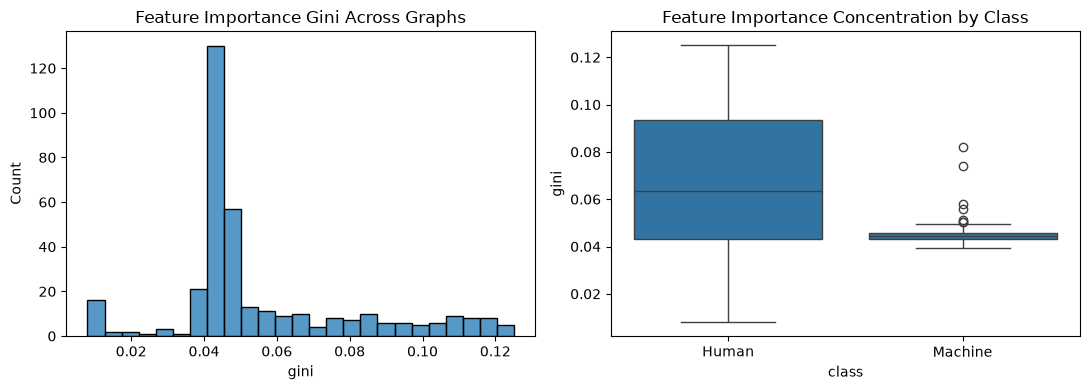

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(
    data=df_un_feat,
    x="gini",
    bins=25,
    ax=axes[0],
)

axes[0].set_title("Feature Importance Gini Across Graphs")

sns.boxplot(
    data=df_un_feat,
    x="class",
    y="gini",
    ax=axes[1],
)

axes[1].set_title("Feature Importance Concentration by Class")

plt.tight_layout()
plt.show()